# 05 — Day 5 Evaluation: Speed-Perturbation Augmentation on HuBERT Layer 12

**Standalone**, duplicating the same handful of reusable pieces as `04_evaluate_trillsson.ipynb` and `permutation_test_hubert_layer12.ipynb`.

**What this tests:** does adding two speed-perturbed copies (0.9x / 1.1x) of every *training* recording to HuBERT layer 12 — the confirmed embedding (AUC 0.611, CI [0.551, 0.683], p = 0.01) — improve on that number? Isolated the same way as every other day: nothing else changes (no PCA, no session-fusion combined in).

**The one rule that matters most here — augmentation must never leak into evaluation:**
- Augmented copies of a recording share that recording's `participant_id`, so grouped LOSO/`GroupKFold(6)` splitting keeps a participant's real *and* augmented data together automatically — same protection as everywhere else in this project.
- But that alone isn't enough here: when a participant is the **outer test** participant, *none* of their data — original or augmented — may appear in the training pool. And whenever a participant's data is being **scored** (as the outer test, or as an inner-CV validation fold), only their **original, unperturbed** recordings are used — never a synthetic copy. Augmented rows exist *only* to enrich a training pool; they are never predicted on. Both rules are enforced explicitly in `nested_loso_cv_augmented` below, not left implicit.

**Inputs needed (Kaggle "Add Input"):**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **`05_features_hubert_augmented`**'s output — for `hubert_layer12_speed_augmented.parquet` (the 0.9x/1.1x embeddings).
3. **Day 3's `01_features.ipynb`** output — for `hubert_base_all_layers.parquet` (the original/unperturbed layer-12 embeddings, reused rather than re-extracted).

## 0. Setup

In [5]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42
LAYER = 12

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
HUBERT_ALL_LAYERS_PARQUET = next(Path("/kaggle/input").rglob("hubert_base_all_layers.parquet"))
AUGMENTED_PARQUET = next(Path("/kaggle/input").rglob("hubert_layer12_speed_augmented.parquet"))

print(f"LABELS_CSV               = {LABELS_CSV}")
print(f"HUBERT_ALL_LAYERS_PARQUET = {HUBERT_ALL_LAYERS_PARQUET}")
print(f"AUGMENTED_PARQUET         = {AUGMENTED_PARQUET}")

LABELS_CSV               = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
HUBERT_ALL_LAYERS_PARQUET = /kaggle/input/notebooks/tappu1/notebook1-day3/features/hubert_base_all_layers.parquet
AUGMENTED_PARQUET         = /kaggle/input/notebooks/tapudatta/day5-aug-features/features/hubert_layer12_speed_augmented.parquet


## 1. Combine Original + Augmented Embeddings

In [6]:
labels = pd.read_csv(LABELS_CSV)
hubert_all_layers = pd.read_parquet(HUBERT_ALL_LAYERS_PARQUET)
augmented = pd.read_parquet(AUGMENTED_PARQUET)

# Pull just layer 12 out of Day 3's all-layers file, renamed to match the augmented file's
# emb_0..emb_1535 column naming, tagged as the speed=1.0 (original) variant.
layer_cols = [c for c in hubert_all_layers.columns if c.startswith(f"layer{LAYER}_emb_")]
assert len(layer_cols) == 1536, f"expected 1536 layer-{LAYER} columns, got {len(layer_cols)}"
original_layer12 = hubert_all_layers[["filename"] + layer_cols].copy()
original_layer12.columns = ["filename"] + [f"emb_{i}" for i in range(1536)]
original_layer12["speed_factor"] = 1.0

augmented = augmented.rename(columns={"source_filename": "filename"})

combined_emb = pd.concat([original_layer12, augmented], ignore_index=True, sort=False)
assert len(combined_emb) == 280 * 3, f"expected 840 combined rows, got {len(combined_emb)}"

df_aug = labels.merge(combined_emb, on="filename", how="inner")
assert len(df_aug) == 280 * 3, f"expected 840 rows after merge, got {len(df_aug)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df_aug["y"] = df_aug["label"].map(LABEL_MAP)
assert df_aug["y"].isna().sum() == 0
df_aug["is_original"] = df_aug["speed_factor"] == 1.0

emb_cols = [c for c in df_aug.columns if c.startswith("emb_")]
X = df_aug[emb_cols].to_numpy()
y = df_aug["y"].to_numpy()
groups = df_aug["participant_id"].to_numpy()
is_original = df_aug["is_original"].to_numpy()

print(f"Total rows: {len(df_aug)} (280 original + 560 augmented)")
print(f"X: {X.shape}, original rows: {is_original.sum()}, augmented rows: {(~is_original).sum()}")

Total rows: 840 (280 original + 560 augmented)
X: (840, 1536), original rows: 280, augmented rows: 560


## 2. Candidates & Augmentation-Aware Nested CV

Same candidate set / `score_fn` / `best_threshold` as every other evaluation notebook. `nested_loso_cv_augmented` below is a modified version of the usual nested LOSO -> `GroupKFold(6)` loop with two changes, both there to prevent augmented data from ever leaking into a score:

- **Outer test set** = only the held-out participant's *original* rows (`groups == test_participant AND is_original`). Their augmented rows are simply unused for that fold — not train, not test.
- **Inner validation folds** = only *original* rows of whichever participants land in the validation split, for the same reason (hyperparameter selection shouldn't be inflated by near-duplicate validation examples either).
- **Training pools** (both outer and inner) use *all* rows — original and augmented — for whichever participants are on the train side. This is where the augmentation actually helps.

In [7]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline(model_name: str, c: float) -> Pipeline:
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def make_candidates():
    return [
        (name, c, build_pipeline(name, c))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [8]:
def nested_loso_cv_augmented(X, y, groups, is_original, n_inner_splits=6):
    participants = np.unique(groups)
    oof_scores = np.full(len(y), np.nan)
    oof_preds = np.full(len(y), -1)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        # Outer test: ONLY this participant's original recordings.
        outer_test_mask = (groups == test_participant) & is_original
        # Outer train: ALL rows (original + augmented) of every OTHER participant.
        # test_participant's augmented rows are excluded by construction (groups != test_participant).
        outer_train_mask = groups != test_participant

        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        is_orig_tr = is_original[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            # Validation: original rows only, from whichever participants landed in this split.
            inner_val_idx = inner_val_idx[is_orig_tr[inner_val_idx]]
            if len(inner_val_idx) == 0:
                continue

            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]        # original + augmented
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]    # original only
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, _, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_name, best_c, best_template = candidates[best_i]

        pooled_inner_scores = np.concatenate(cand_scores[best_i])
        pooled_inner_labels = np.concatenate(cand_labels[best_i])
        threshold = best_threshold(pooled_inner_scores, pooled_inner_labels)

        final_pipe = clone(best_template).fit(X_tr, y_tr)   # trained on original + augmented
        test_scores = score_fn(final_pipe, X_te)             # scored on original only

        test_positions = np.where(outer_test_mask)[0]
        oof_scores[test_positions] = test_scores
        oof_preds[test_positions] = (test_scores >= threshold).astype(int)

        fold_records.append({
            "test_participant": test_participant,
            "n_test": int(outer_test_mask.sum()),
            "n_train": int(outer_train_mask.sum()),
            "chosen_model": best_name,
            "chosen_C": best_c,
            "inner_cv_auc": mean_aucs[best_i],
            "threshold": threshold,
        })

    print(f"Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    n_scored = np.sum(~np.isnan(oof_scores))
    print(f"Scored {n_scored} original recordings (expected 280).")
    assert n_scored == 280, f"expected exactly 280 scored original recordings, got {n_scored}"
    return oof_scores, oof_preds, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}
    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))
    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)

## 3. Run & Compare

In [9]:
oof_scores, oof_preds, fold_info = nested_loso_cv_augmented(X, y, groups, is_original)

valid = ~np.isnan(oof_scores)
y_orig = y[valid]
oof_scores_orig = oof_scores[valid]
oof_preds_orig = oof_preds[valid]
groups_orig = groups[valid]

pooled_auc = roc_auc_score(y_orig, oof_scores_orig)
balanced_acc = balanced_accuracy_score(y_orig, oof_preds_orig)
f1 = f1_score(y_orig, oof_preds_orig)
ci_lo, ci_hi, _ = bootstrap_auc_ci(groups_orig, y_orig, oof_scores_orig)

print(f"Augmented pooled ROC-AUC: {pooled_auc:.3f}  (95% CI: [{ci_lo:.3f}, {ci_hi:.3f}])")
print(f"Balanced accuracy: {balanced_acc:.3f}   F1: {f1:.3f}")
fold_info

Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
Scored 280 original recordings (expected 280).
Augmented pooled ROC-AUC: 0.639  (95% CI: [0.576, 0.705])
Balanced accuracy: 0.613   F1: 0.594


,test_participant,n_test,n_train,chosen_model,chosen_C,inner_cv_auc,threshold
0,P-33B7FA2A,6,822,logreg,0.001,0.672834,0.558310
1,P-4B5527A7,21,777,logreg,0.010,0.669148,0.419306
2,P-4F8CDB03,20,780,logreg,0.001,0.651192,0.549290
3,P-57C20427,42,714,logreg,0.001,0.641874,0.341940
4,P-5AE2B073,6,822,logreg,0.010,0.679086,0.620647
5,P-66395191,21,777,logreg,0.001,0.647057,0.462429
6,P-7DB1F098,42,714,logreg,10.000,0.656120,0.891570
7,P-87C2E2A3,21,777,logreg,0.001,0.654521,0.536768
8,P-8A4B73A3,11,807,logreg,0.001,0.655022,0.566672
9,P-B116746A,12,804,logreg,10.000,0.680932,0.854178


                                variant      auc    ci_lo    ci_hi
HuBERT L12 (confirmed, no augmentation) 0.611000 0.551000 0.683000
                        Day 4 TRILLsson 0.590000 0.535000 0.651000
  Day 5 HuBERT L12 + speed augmentation 0.639302 0.575941 0.705028


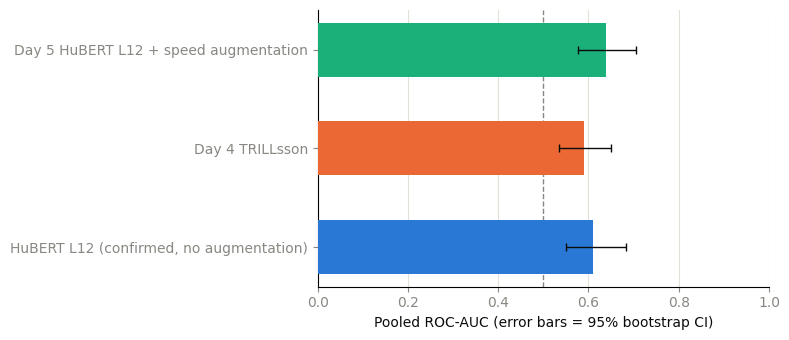

In [10]:
reference = pd.DataFrame([
    {"variant": "HuBERT L12 (confirmed, no augmentation)", "auc": 0.611, "ci_lo": 0.551, "ci_hi": 0.683},
    {"variant": "Day 4 TRILLsson", "auc": 0.590, "ci_lo": 0.535, "ci_hi": 0.651},
    {"variant": "Day 5 HuBERT L12 + speed augmentation", "auc": pooled_auc, "ci_lo": ci_lo, "ci_hi": ci_hi},
])
print(reference.to_string(index=False))

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 3.5))
y_pos = np.arange(len(reference))
ax.barh(y_pos, reference["auc"], color=COLORS[: len(reference)], height=0.55, zorder=3)
ax.errorbar(
    reference["auc"], y_pos,
    xerr=[reference["auc"] - reference["ci_lo"], reference["ci_hi"] - reference["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(reference["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## How to read Day 5's results

**Context worth having before reading the number:** speaking rate is a genuinely well-documented fatigue marker in the speech literature — slower articulation, more/longer pauses, and increased total speech time all correlate with fatigue in prior research. That makes speed-perturbation augmentation a real gamble, not just a free win: by assigning the *same* fatigue label to a recording's original, 10%-slower, and 10%-faster copies, this technique explicitly trains the classifier toward tempo-invariance. If HuBERT layer 12's 0.611 result is partly *because* it's picking up on genuine tempo differences, this augmentation is directly fighting that signal, not just adding harmless variety — that's a sharper and more likely explanation for a drop than the pitch-shift side effect alone.

- **Clearly above 0.611** (not a hair's-width move): the extra training volume outweighed the tempo-invariance cost — augmentation is a genuine improvement, and this becomes the new base going into Day 6 (combination with PCA/session-fusion tried on top of it).
- **Roughly at 0.611, CI substantially overlapping the un-augmented result**: augmentation neither helped nor hurt in a way we can distinguish from noise — reasonable to drop it for simplicity (per `PROJECT_PLAN.md`'s "Simplicity First" guidance) and carry the plain HuBERT L12 result into Day 6 instead.
- **Below 0.611**: consistent with the tempo-invariance conflict described above — evidence that tempo is likely one of the real channels this embedding uses for fatigue, and that forcing invariance to it actively hurts. Worth reporting as a finding in its own right (it tells us something about *how* HuBERT L12 is picking up the signal), and a reason to not carry augmentation into Day 6.

Update `PROJECT_PLAN.md`'s Day 5 entry either way before moving to Day 6.